In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Regression Libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error, r2_score

# Time Series Libraries
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

import warnings
warnings.filterwarnings('ignore')

## Accra Data Loading and Filtering
- After loading the raw CSV file into our jupyter notebook, we filtered the location column to keep only the rows containing the word **Accra**. We did this because including properties from outside our target area would introduce unnecessary noise and skew our final predictions.

In [3]:
# Load the dataset
df_raw = pd.read_csv("Accra Housing .csv")

# Isolate the Accra market specifically
df_raw = df_raw[df_raw['location'].str.contains('Accra', case=False, na=False)].copy()

df_raw.head(2)

,url,Date,listing_type,name,price,category,bedrooms,bathrooms,floor_area,location,condition,amenities,region,locality,parking_space,is_furnished,lat,lng
0,https://tonaton.com/a-MfYFNdCgCTytOcmvZIh0Kzrj...,6/2/2023,rentals,"2bdrm Apartment in Charclem Ventures, East Leg...",9196,Flats,2,2,145,"Greater Accra, East Legon",Used,"24-hour Electricity,Air Conditioning,Balcony,C...",Greater Accra,East Legon,False,Semi-Furnished,5.635828,-0.161359
1,https://tonaton.com/a-MfYFNdCgwtb8Itol9odpMPvC...,22/05/2023,rentals,"2bdrm Apartment in , Dzorwulu for rent",7500,Flats,2,2,100,"Greater Accra, Dzorwulu",Used,"24-hour Electricity,Air Conditioning,Apartment...",Greater Accra,Dzorwulu,False,Unfurnished,5.614123,-0.195647


In [17]:
print(f"The Original Dataset has {df_raw.shape[0]} rows and {df_raw.shape[1]} columns:")

print("\n--- Dataset Info ---\n")
df_raw.info()


print("\n--- Missing Values ---")
print(df_raw.isnull().sum())

The Original Dataset has 16549 rows and 18 columns:

--- Dataset Info ---

<class 'pandas.core.frame.DataFrame'>
Index: 16549 entries, 0 to 17889
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   url            16549 non-null  object 
 1   Date           3985 non-null   object 
 2   listing_type   16549 non-null  object 
 3   name           16549 non-null  object 
 4   price          16549 non-null  int64  
 5   category       16549 non-null  object 
 6   bedrooms       16549 non-null  int64  
 7   bathrooms      16549 non-null  int64  
 8   floor_area     16549 non-null  int64  
 9   location       16549 non-null  object 
 10  condition      16549 non-null  object 
 11  amenities      16549 non-null  object 
 12  region         16549 non-null  object 
 13  locality       16549 non-null  object 
 14  parking_space  16549 non-null  bool   
 15  is_furnished   16549 non-null  object 
 16  lat            16549 non

# Statistical Analysis Report.
- The **Original** Dataset has 16549 rows and 18 columns

In [8]:
print("\n--- Statistical Summary ---")
display(df_raw[['price', 'bedrooms', 'bathrooms', 'floor_area']].describe().round(2))


--- Statistical Summary ---


,price,bedrooms,bathrooms,floor_area
count,16549.00,16549.00,16549.00,16549.00
mean,8393.72,2.46,2.59,585.67
std,10611.05,1.24,1.37,1076.55
min,420.00,1.00,1.00,10.00
25%,2000.00,2.00,2.00,100.00
50%,4000.00,2.00,2.00,145.00
75%,10120.00,3.00,3.00,648.00
max,59524.00,20.00,20.00,5000.00


## Visualisation for Accra Housing Dataset

## Data Distribution Visualization
- We plotted a price distribution histogram to observe the skewness of the market, a bar chart to validate our assumption that more bedrooms generally lead to higher prices, and a correlation heatmap to identify how strongly numerical features relate to the price and to check for multicollinearity, which can confuse linear models.

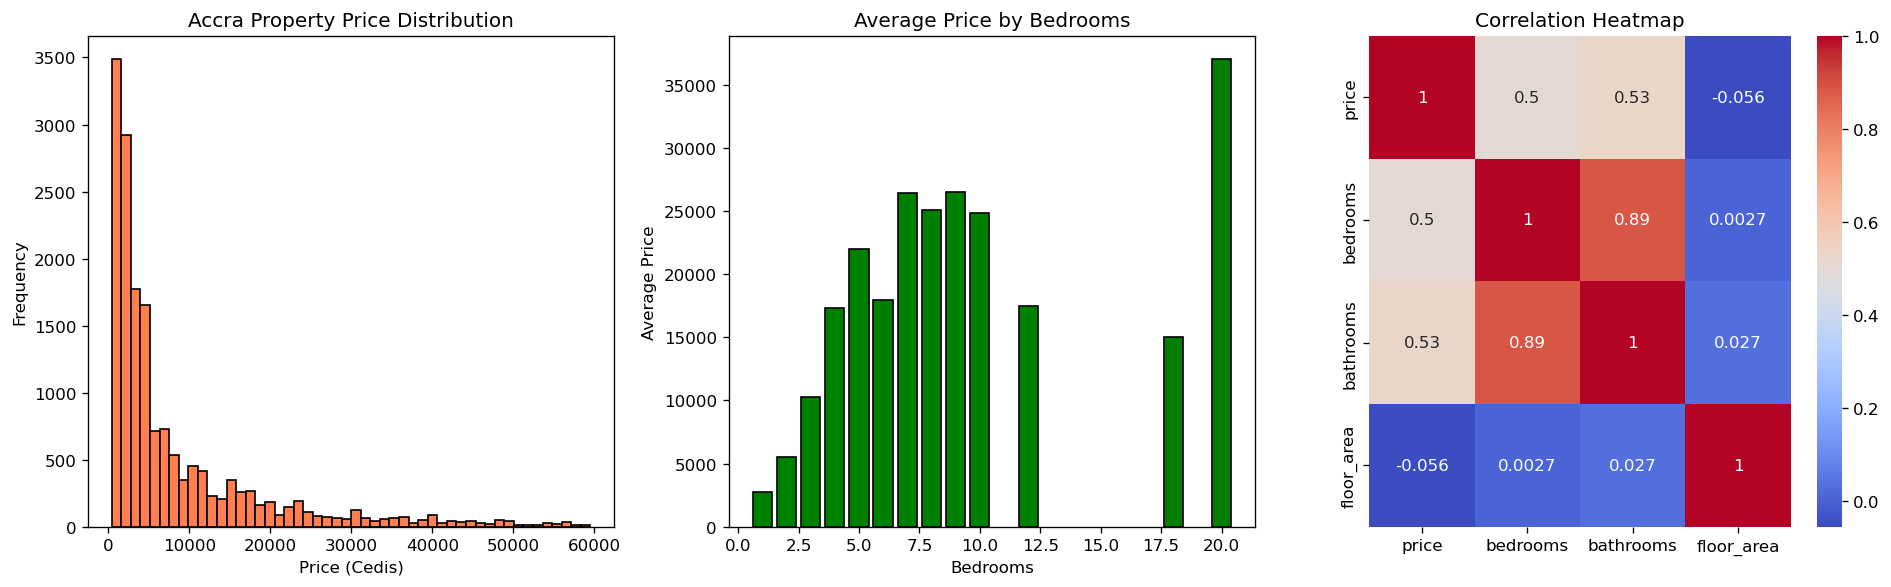

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=120)

# 1. Price Distribution
axes[0].hist(df_raw['price'], bins=50, color='coral', edgecolor='black')
axes[0].set_title('Accra Property Price Distribution')
axes[0].set_xlabel('Price (Cedis)')
axes[0].set_ylabel('Frequency')
axes[0].ticklabel_format(style='plain', axis='x')

# 2. Average Price by Bedrooms
avg_price = df_raw.groupby('bedrooms')['price'].mean().round(2)
axes[1].bar(avg_price.index, avg_price.values, color='green', edgecolor='black')
axes[1].set_title('Average Price by Bedrooms')
axes[1].set_xlabel('Bedrooms')
axes[1].set_ylabel('Average Price')
axes[1].ticklabel_format(style='plain', axis='y') 

# 3. Correlation Heatmap (Numeric only)
sns.heatmap(df_raw[['price', 'bedrooms', 'bathrooms', 'floor_area']].corr(), 
            annot=True, cmap='coolwarm', ax=axes[2])
axes[2].set_title('Correlation Heatmap')

plt.tight_layout()
plt.show()

## Feature Engineering & Preprocessing for Regression
- To prepare the dataset for regression, we first dropped text-heavy and columns we wont be using like URLs and exact dates since machine learning models require strict numerical inputs.
- We noticed an anomaly where floor_area was '100', so we replaced those values with the median floor area of similar houses (matching both category and bedroom count) to preserve the data rather than blindly deleting the rows.
- We also extracted valuable text data from the amenities column into binary features (1 or 0), applied a log transformation ($y = \ln(x)$) to our skewed price and area columns to make them more normally distributed.
- We finally converted categorical variables like neighborhoods into mathematical dummy variables. 

In [19]:
# Create a copy specifically for regression (dropping Date to save 12k rows)
df_reg = df_raw.copy()

# Drop columns not needed for regression
cols_to_drop = ['url', 'name', 'Date', 'listing_type', 'location', 'region', 'lat', 'lng']
df_reg.drop(columns=[c for c in cols_to_drop if c in df_reg.columns], inplace=True)

# Fix the '100' floor_area imputation anomaly
df_reg['floor_area'] = df_reg['floor_area'].replace(100, np.nan)
df_reg['floor_area'] = df_reg['floor_area'].fillna(df_reg.groupby(['category', 'bedrooms'])['floor_area'].transform('median'))
df_reg['floor_area'] = df_reg['floor_area'].fillna(df_reg['floor_area'].median()) 

# Extract premium amenities into binary numeric columns
if 'amenities' in df_reg.columns:
    df_reg['has_ac'] = df_reg['amenities'].str.contains('Air Conditioning', case=False, na=False).astype(int)
    df_reg['has_generator'] = df_reg['amenities'].str.contains('Generator', case=False, na=False).astype(int)
    df_reg['has_security'] = df_reg['amenities'].str.contains('Security', case=False, na=False).astype(int)
    df_reg.drop(columns=['amenities'], inplace=True)

# Drop any remaining rows where the target (price) is missing
df_reg.dropna(subset=['price'], inplace=True)

# Log transform Price and Floor Area to fix skewness
df_reg['log_price'] = np.log(df_reg['price'])
df_reg['log_sqft'] = np.log(df_reg['floor_area'])
df_reg.drop(columns=['price', 'floor_area'], inplace=True)

# Create Dummy Variables for categorical text columns
df_reg = pd.get_dummies(df_reg, drop_first=True)

# Define Features (X) and Target (y)
X = df_reg.drop(columns=['log_price'])
y = df_reg['log_price']

print("Regression dataset ready. Number of features:", X.shape[1])

Regression dataset ready. Number of features: 97


# Model building & Evaluation
- We split our processed data into an 80% training set and a 20% testing set so we could evaluate our models on unseen data, ensuring they were actually learning patterns instead of just memorizing the training records. We then trained a standard Linear Regression model alongside Lasso ($L_1$) and Ridge ($L_2$) regression models.
  
- Since our dummy encoding created **97** features, **standard linear regression** is highly prone to overfitting; therefore, we used Lasso and Ridge to apply regularization, which **shrinks or penalizes** less important coefficients to make the model more generalized and stable

In [30]:
# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)
lr_r2 = r2_score(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))

# 2. Lasso Regression
lasso_model = Lasso(alpha=0.01, random_state=42) 
lasso_model.fit(X_train, y_train)
lasso_pred = lasso_model.predict(X_test)
lasso_r2 = r2_score(y_test, lasso_pred)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_pred))

# 3. Ridge Regression
ridge_model = Ridge(alpha=10.0, random_state=42)
ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)
ridge_r2 = r2_score(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))

# Compare Results
comparison_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Lasso (L1)', 'Ridge (L2)'],
    'R-Squared': [lr_r2, lasso_r2, ridge_r2],
    'RMSE': [lr_rmse, lasso_rmse, ridge_rmse]
})

print("--- Regression Models Comparison ---")
display(comparison_df)

# --- NEW: Intercepts & Coefficients ---
print("\n--- Model Intercepts ---")
print(f"Linear Regression Intercept: {lr_model.intercept_:.4f}")
print(f"Lasso Intercept: {lasso_model.intercept_:.4f}")
print(f"Ridge Intercept: {ridge_model.intercept_:.4f}")

print("\n--- Ridge Regression Coefficients (Top 10 Most Impactful) ---")
# Create a DataFrame for the Ridge coefficients (our chosen model)
# Sorting by absolute value shows the features with the strongest push on price (up or down)
ridge_coefs = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': ridge_model.coef_,
    'Intercept': ridge_model.intercept_
}).sort_values(by='Coefficient', key=abs, ascending=False)

display(ridge_coefs.head(10))

--- Regression Models Comparison ---


,Model,R-Squared,RMSE
0,Linear Regression,0.795851,0.504805
1,Lasso (L1),0.736618,0.573380
2,Ridge (L2),0.793780,0.507359



--- Model Intercepts ---
Linear Regression Intercept: 8.5107
Lasso Intercept: 7.5954
Ridge Intercept: 8.0058

--- Ridge Regression Coefficients (Top 10 Most Impactful) ---


,Feature,Coefficient,Intercept
36,locality_Cantonments,1.119301,8.005809
52,locality_Kasoa,-0.921313,8.005809
96,is_furnished_Unfurnished,-0.879145,8.005809
57,locality_Labone,0.866920,8.005809
95,is_furnished_Semi-Furnished,-0.865385,8.005809
81,locality_Ridge,0.707806,8.005809
82,locality_Roman Ridge,0.695092,8.005809
44,locality_Dzorwulu,0.691245,8.005809
25,locality_Airport Residential Area,0.668757,8.005809
77,locality_Osu,0.594684,8.005809


# Model Selection: Ridge Regression
Although the Linear Regression model also achieved the higher R-squared of 0.795 and the lowest RMSE of 0.504 on this specific test split, Ridge Regression is the best overall choice for this market analysis.

## Here is why:

`Handling High Dimensionality:` Our preprocessing pipeline generated 97 features, largely due to one-hot encoding the various Accra neighborhoods into dummy variables. Standard Linear Regression is highly prone to overfitting in high-dimensional spaces, meaning it tends to memorize the training data rather than learning the true underlying market rules.

`Stability Through Regularization:` Ridge regression applies an L2 penalty, which mathematically restricts the coefficients of highly correlated features. In real estate, features like square footage, bedrooms, and premium amenities often overlap in how they influence price. Ridge spreads the weights more evenly across these variables, preventing any single feature from destabilizing the predictions.

`The Generalization Trade-off:` The Ridge model's performance metrics are nearly identical to the standard Linear model (an R-squared of 0.793 vs 0.795). Sacrificing that tiny fraction of accuracy on the test set is a highly worthwhile trade-off to secure a robust, generalized model that will perform much more reliably on future, unseen property listings.

## Interpreting the Intercepts and Coefficients
- We printed the intercept (model.intercept_) for all three models. In linear regression, the intercept represents the baseline starting value of the target variable when all other features are exactly zero. Because we log-transformed our prices earlier, this number represents the baseline log price of an Accra property before factoring in bedrooms, size, or location.

In [32]:
def predict_property_price(bedrooms, bathrooms, floor_area, has_ac, has_generator, has_security, 
                           category, condition, locality, is_furnished):
    """
    Takes human-readable property details, encodes them to match the trained Ridge model,
    and returns the predicted price in Cedis.
    """
    # 1. Create a dictionary with every training column set to 0 initially
    input_dict = {col: 0 for col in X.columns}
    
    # 2. Update our specific numeric inputs
    input_dict['bedrooms'] = bedrooms
    input_dict['bathrooms'] = bathrooms
    input_dict['log_sqft'] = np.log(floor_area) # Apply log transformation
    input_dict['has_ac'] = has_ac
    input_dict['has_generator'] = has_generator
    input_dict['has_security'] = has_security
    
    # 3. Create a list of our text categories and turn their specific columns to 1
    categories = [f"category_{category}", f"condition_{condition}", 
                  f"locality_{locality}", f"is_furnished_{is_furnished}"]
    
    for col in categories:
        if col in input_dict:
            input_dict[col] = 1
            
    # 4. Convert the dictionary into a pandas DataFrame and predict
    input_df = pd.DataFrame([input_dict])
    predicted_log_price = ridge_model.predict(input_df)[0]
    
    # 5. Inverse the log transformation to get the actual Cedis price
    predicted_price = np.exp(predicted_log_price)
    
    return predicted_price

# --- Example Prediction ---
estimated_price = predict_property_price(
    bedrooms=3, bathrooms=2, floor_area=150, has_ac=1, has_generator=0, has_security=1,
    category='Flats', condition='Used', locality='East Legon', is_furnished='Unfurnished'
)

print(f"Estimated Property Price: ₵ {estimated_price:,.2f}")

Estimated Property Price: ₵ 7,007.20


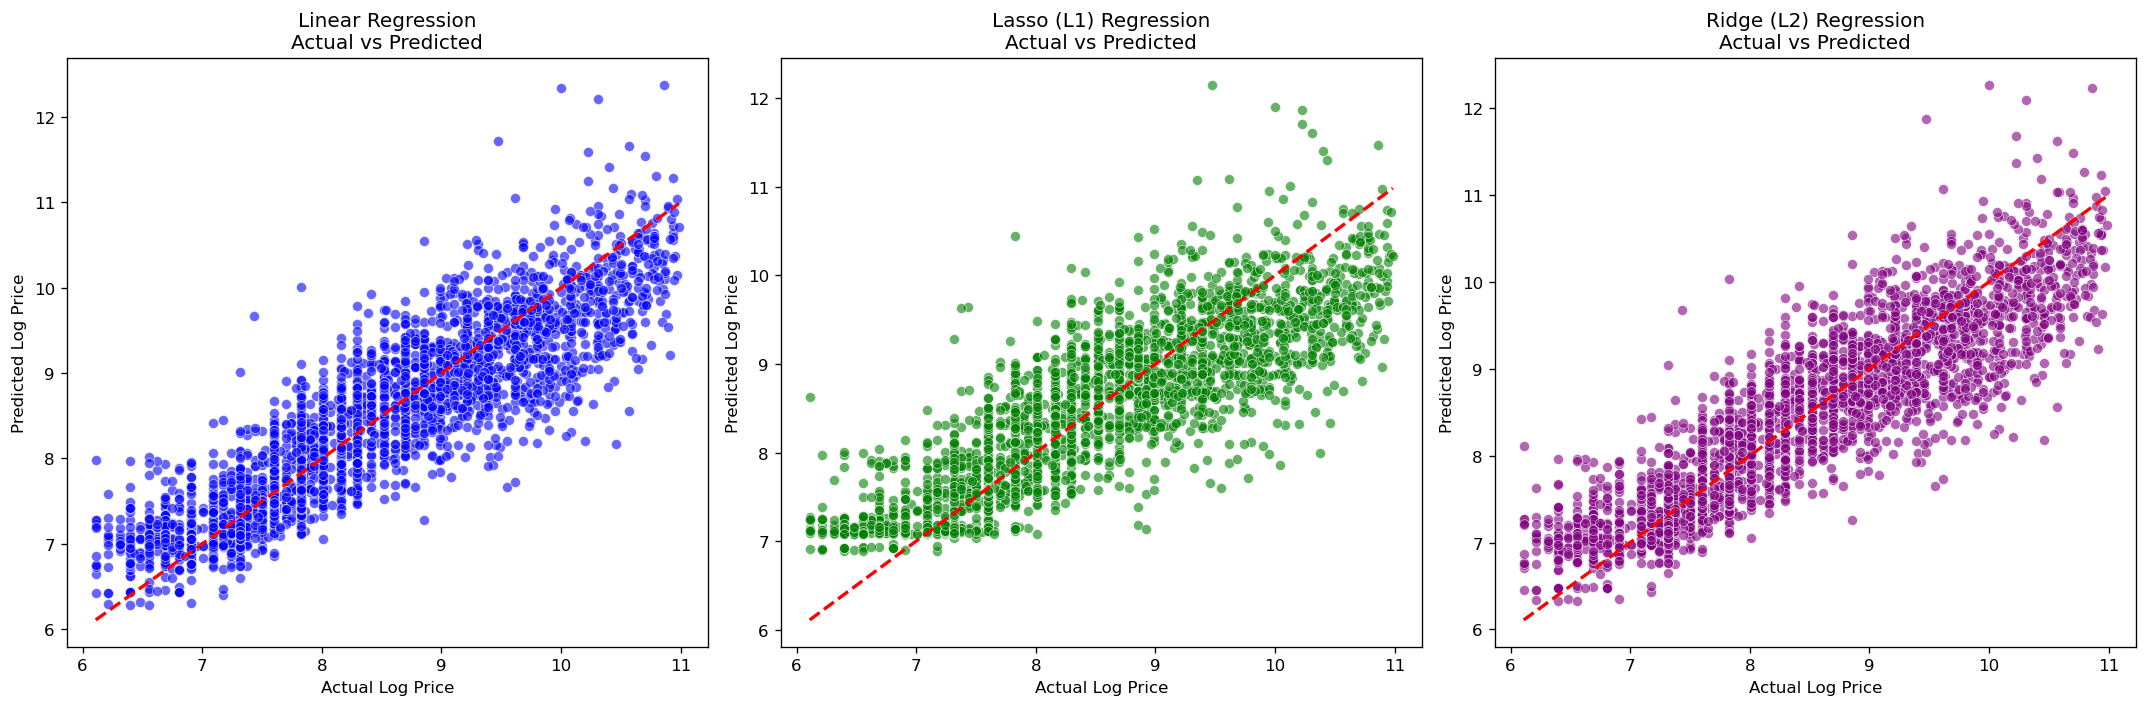

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=120)

# 1. Linear Regression Plot
sns.scatterplot(x=y_test, y=lr_pred, ax=axes[0], alpha=0.6, color='blue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title('Linear Regression\nActual vs Predicted')
axes[0].set_xlabel('Actual Log Price')
axes[0].set_ylabel('Predicted Log Price')

# 2. Lasso Regression Plot
sns.scatterplot(x=y_test, y=lasso_pred, ax=axes[1], alpha=0.6, color='green')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[1].set_title('Lasso (L1) Regression\nActual vs Predicted')
axes[1].set_xlabel('Actual Log Price')
axes[1].set_ylabel('Predicted Log Price')

# 3. Ridge Regression Plot
sns.scatterplot(x=y_test, y=ridge_pred, ax=axes[2], alpha=0.6, color='purple')
axes[2].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[2].set_title('Ridge (L2) Regression\nActual vs Predicted')
axes[2].set_xlabel('Actual Log Price')
axes[2].set_ylabel('Predicted Log Price')

plt.tight_layout()
plt.show()

## Time Series Analysis

In [15]:
# Create a copy specifically for Time Series (dropping rows missing Dates)
df_ts = df_raw.copy()
df_ts = df_ts.dropna(subset=['Date'])

# Convert Date to datetime format and set as index
df_ts['Date'] = pd.to_datetime(df_ts['Date'], dayfirst=True, errors='coerce')
df_ts = df_ts.dropna(subset=['Date']) 
df_ts.set_index('Date', inplace=True)

# Sort chronologically (Required for time series)
df_ts.sort_index(inplace=True)

# Resample data to get the average housing price per Month ('M')
monthly_prices = df_ts['price'].resample('M').mean()

# Forward-fill any blank months to maintain a continuous timeline
monthly_prices = monthly_prices.ffill()

print("Time Series data ready. Number of monthly periods:", len(monthly_prices))

Time Series data ready. Number of monthly periods: 36


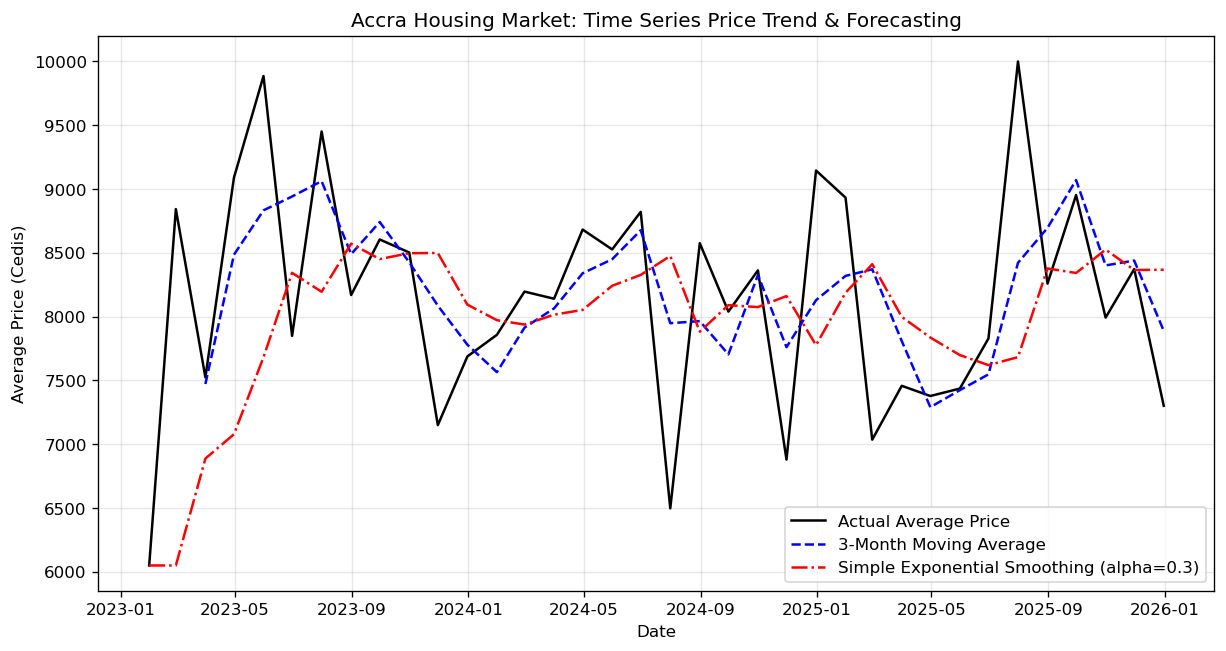

In [16]:
# 1. Model 1: 3-Month Simple Moving Average (SMA)
moving_avg_3m = monthly_prices.rolling(window=3).mean()

# 2. Model 2: Simple Exponential Smoothing (SES)
# Using a smoothing level (alpha) of 0.3
ses_model = SimpleExpSmoothing(monthly_prices).fit(smoothing_level=0.3, optimized=False)
ses_forecast = ses_model.fittedvalues

# Visualize the Time Series Models
plt.figure(figsize=(12, 6), dpi=120)
plt.plot(monthly_prices.index, monthly_prices.values, label='Actual Average Price', color='black', linewidth=1.5)
plt.plot(moving_avg_3m.index, moving_avg_3m.values, label='3-Month Moving Average', color='blue', linestyle='--')
plt.plot(ses_forecast.index, ses_forecast.values, label='Simple Exponential Smoothing (alpha=0.3)', color='red', linestyle='-.')

plt.title('Accra Housing Market: Time Series Price Trend & Forecasting')
plt.xlabel('Date')
plt.ylabel('Average Price (Cedis)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()